<a href="https://colab.research.google.com/github/Elight-dotcom/data-mining/blob/main/DM_M10_3124600100_Ardanu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M9 - Clustering - Data Mining

Nama : Ardanu Egitya Ash Shafah  
NRP : 3124600100  
Kelas : D4 IT D

In [122]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## 1. dataset

Membaca `transaction.csv` ke dalam DataFrame pandas dan menyimpannya di variabel `dataset`, lalu menampilkannya.

In [124]:
data_path = '/content/drive/MyDrive/PENS/Semester 5/Data Mining/transaction.csv'

dataset = pd.read_csv(data_path)

dataset

,InvoiceNo,StockCode,Qty,InvoiceDate,CustomerID,Country
0,537626,22725,830,12/7/2010 14:57,12347,Iceland
1,537626,22729,948,12/7/2010 14:57,12347,Iceland
2,537626,22195,695,12/7/2010 14:57,12347,Iceland
3,542237,22725,636,1/26/2011 14:30,12347,Iceland
4,542237,22729,536,1/26/2011 14:30,12347,Iceland
...,...,...,...,...,...,...
10541,543911,21700,455,2/14/2011 12:46,17829,United Arab Emirates
10542,543911,22111,578,2/14/2011 12:46,17829,United Arab Emirates
10543,543911,22112,163,2/14/2011 12:46,17829,United Arab Emirates
10544,564428,23296,545,8/25/2011 11:27,17844,Canada


In [125]:
print("Jumlah baris :", dataset.shape[0])
print("Jumlah kolom :", dataset.shape[1])
dataset.info()

Jumlah baris : 10546
Jumlah kolom : 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10546 entries, 0 to 10545
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   InvoiceNo    10546 non-null  int64 
 1   StockCode    10546 non-null  int64 
 2   Qty          10546 non-null  int64 
 3   InvoiceDate  10546 non-null  object
 4   CustomerID   10546 non-null  int64 
 5   Country      10546 non-null  object
dtypes: int64(4), object(2)
memory usage: 494.5+ KB


## 2. country

Menghitung berapa kali tiap negara muncul pada dataset (jumlah baris per negara), disimpan di `country`.

In [126]:
country = dataset["Country"].value_counts()
country

,count
Country,
Germany,2269
France,2109
EIRE,1620
Netherlands,634
Spain,539
Belgium,486
Switzerland,434
Portugal,367
Australia,356


## 3. transaksi

Menghitung rata-rata jumlah barang (`Qty`) per transaksi pada tiap negara. Satu kode `InvoiceNo` = satu transaksi, sehingga `Qty` dijumlahkan dulu per `InvoiceNo`, lalu dirata-rata per negara.  
Hasil disimpan di `transaksi`. Urutan negara mengikuti urutan abjad (hasil `groupby`).

In [127]:
qty_per_invoice = dataset.groupby(["Country", "InvoiceNo"])["Qty"].sum()
transaksi = qty_per_invoice.groupby("Country").mean()
transaksi.name = "Transaksi"
transaksi

,Transaksi
Country,
Australia,4026.295455
Austria,3420.250000
Bahrain,1470.000000
Belgium,3032.714286
Brazil,4389.000000
Canada,6449.666667
Channel Islands,4569.714286
Cyprus,3550.875000
Czech Republic,1239.500000


## 4. cluster_i dan cluster_val

K-Means dengan **k = 3** dijalankan 10 kali (`random_state` berbeda, `n_init=1`) agar inisialisasi centroid berbeda tiap run. Setiap hasil clustering dievaluasi dengan **SSE** (jumlah kuadrat jarak tiap titik ke centroid clusternya).  
`cluster_i` menyimpan model tiap run, `cluster_val` menyimpan SSE-nya. Indeks list 0-9 mewakili run ke-1 sampai ke-10.

In [128]:
X = transaksi.values.reshape(-1, 1)

cluster_i = []
cluster_val = []
for i in range(10):
    model = KMeans(n_clusters=3, init='random', n_init=1)
    model.fit_predict(X)
    sse = model.inertia_
    cluster_i.append(model)
    cluster_val.append(sse)

pd.DataFrame({"Run": range(1, 11), "SSE": cluster_val})

,Run,SSE
0,1,1.634692e+07
1,2,1.322911e+07
2,3,1.322911e+07
3,4,1.322911e+07
4,5,1.642099e+07
5,6,1.322911e+07
6,7,1.642099e+07
7,8,1.322911e+07
8,9,1.322911e+07
9,10,1.322911e+07


## 5. cluster

Mengambil `cluster_i` dengan `cluster_val` (SSE) terkecil. Label cluster (0, 1, 2) disimpan di `cluster`; nomor labelnya hanya penanda dan belum menunjukkan tingkat transaksi.

In [129]:
best = int(np.argmin(cluster_val))
model = cluster_i[best]
cluster = model.labels_

print(f"Run terbaik = {best + 1}, SSE = {cluster_val[best]:.2f}\n")
pd.DataFrame({"Country": transaksi.index, "Transaksi": transaksi.values, "Cluster": cluster})

Run terbaik = 2, SSE = 13229107.20



,Country,Transaksi,Cluster
0,Australia,4026.295455,0
1,Austria,3420.250000,0
2,Bahrain,1470.000000,2
3,Belgium,3032.714286,0
4,Brazil,4389.000000,0
5,Canada,6449.666667,1
6,Channel Islands,4569.714286,0
7,Cyprus,3550.875000,0
8,Czech Republic,1239.500000,2
9,Denmark,3018.888889,0


## 6. centroid

Posisi centroid tiap cluster diambil dari `cluster_centers_` model terbaik. Hasil disimpan di `centroid` (indeks = label cluster).

In [130]:
centroid = pd.Series(
    model.cluster_centers_.flatten(),
    index=range(3),
    name="Centroid",
)
centroid.index.name = "Cluster"
centroid

,Centroid
Cluster,
0,3542.219521
1,6173.850813
2,1400.130342


## 7. sorted
Mengurutkan posisi centroid secara **ascending**. Indeks pada hasil pengurutan tetap berisi label cluster asalnya, sehingga bisa dipakai untuk memetakan cluster ke kategori. Hasil disimpan di `sorted`.

> Catatan: nama `sorted` sesuai permintaan, tetapi nama ini menimpa fungsi bawaan Python `sorted()`. Notebook ini tidak memakai fungsi tersebut lagi setelah sel ini.

In [131]:
sorted = centroid.sort_values(ascending=True)
sorted

,Centroid
Cluster,
2,1400.130342
0,3542.219521
1,6173.850813


## 8. Kategori transaksi rendah, sedang, dan tinggi

- Indeks **pertama** pada `sorted` → cluster transaksi **rendah**
- Indeks **terakhir** pada `sorted` → cluster transaksi **tinggi**
- Indeks **di antaranya** → cluster transaksi **sedang**

In [132]:
label_rendah = sorted.index[0]
label_sedang = list(sorted.index[1:-1])
label_tinggi = sorted.index[-1]

kategori = {label_rendah: "Rendah", label_tinggi: "Tinggi"}
for k in label_sedang:
    kategori[k] = "Sedang"

hasil = pd.DataFrame({
    "Country": transaksi.index,
    "Transaksi": transaksi.values,
    "Cluster": cluster,
})
hasil["Kategori"] = hasil["Cluster"].map(kategori)

print(f"Cluster rendah = {label_rendah}, sedang = {label_sedang}, tinggi = {label_tinggi}\n")
for nama in ["Rendah", "Sedang", "Tinggi"]:
    daftar = hasil[hasil["Kategori"] == nama]
    print(f"Transaksi {nama.upper()} ({len(daftar)} negara):")
    print(", ".join(daftar["Country"]))
    print()

Cluster rendah = 2, sedang = [0], tinggi = 1

Transaksi RENDAH (6 negara):
Bahrain, Czech Republic, European Community, Lithuania, Saudi Arabia, Sweden

Transaksi SEDANG (23 negara):
Australia, Austria, Belgium, Brazil, Channel Islands, Cyprus, Denmark, EIRE, Finland, France, Germany, Greece, Iceland, Italy, Japan, Lebanon, Malta, Netherlands, Norway, Poland, Portugal, Spain, Unspecified

Transaksi TINGGI (7 negara):
Canada, Israel, RSA, Singapore, Switzerland, USA, United Arab Emirates



In [133]:
hasil

,Country,Transaksi,Cluster,Kategori
0,Australia,4026.295455,0,Sedang
1,Austria,3420.250000,0,Sedang
2,Bahrain,1470.000000,2,Rendah
3,Belgium,3032.714286,0,Sedang
4,Brazil,4389.000000,0,Sedang
5,Canada,6449.666667,1,Tinggi
6,Channel Islands,4569.714286,0,Sedang
7,Cyprus,3550.875000,0,Sedang
8,Czech Republic,1239.500000,2,Rendah
9,Denmark,3018.888889,0,Sedang


## 9. Visualisasi

Scatter plot dengan warna berbeda untuk tiap kategori hasil cluster. Sumbu x = urutan country, sumbu y = jumlah transaksi.

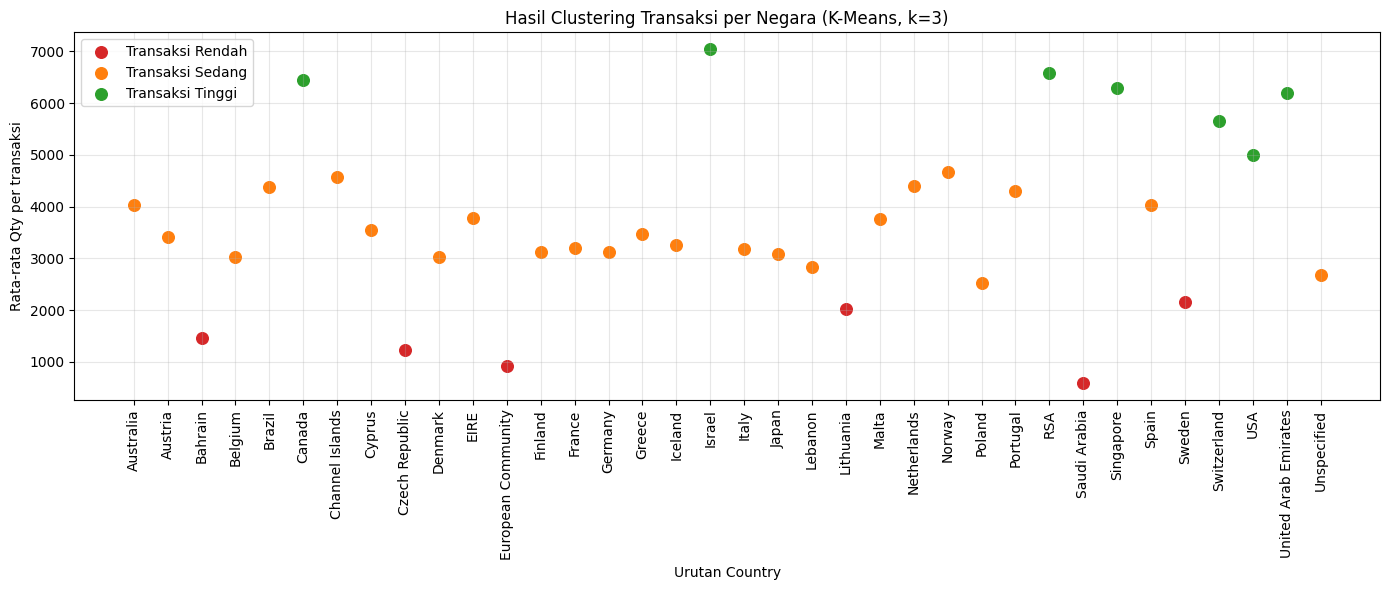

In [134]:
warna = {"Rendah": "tab:red", "Sedang": "tab:orange", "Tinggi": "tab:green"}
x = np.arange(len(hasil))

plt.figure(figsize=(14, 6))
for nama in ["Rendah", "Sedang", "Tinggi"]:
    m = (hasil["Kategori"] == nama).values
    plt.scatter(x[m], hasil["Transaksi"][m], c=warna[nama], s=70, label=f"Transaksi {nama}")

plt.xticks(x, hasil["Country"], rotation=90)
plt.xlabel("Urutan Country")
plt.ylabel("Rata-rata Qty per transaksi")
plt.title("Hasil Clustering Transaksi per Negara (K-Means, k=3)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()